# NILM Baseline/Ablation -- CNN + BiLSTM

**Model:** CNN + BiLSTM
**Input:** Preprocessed power signal only
**Attention:** NO
**Knowledge Vector:** NO
**Target Appliances:** Dishwasher, Washing Machine, Laptop, Fridge, Office Lamp 1
**Experiment Purpose:** Baseline/ablation comparison for the NILM research project --
isolating the contribution of CNN feature extraction feeding a BiLSTM before temporal attention and knowledge-vector
fusion are added in the full research model.

This notebook uses the **same preprocessing pipeline** as the rest of the project (synthetic
aggregate of the 5 selected appliances, median filtering, day-cycled 7:1:2 split, 100-sample
sliding windows, MinMax scaling) so that this comparison and the later knowledge-fusion
results remain apples-to-apples.


## 1. Install & Imports

In [ ]:
!pip install -q tensorflow scikit-learn scipy pandas numpy matplotlib

In [ ]:
import os, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                              accuracy_score, mean_absolute_error, classification_report)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

RANDOM_SEED = 42
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Mount Drive & Configuration

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# Configuration -- EDIT dataset path here. Everything else in this
# cell is fixed identically across all three baseline notebooks.
# ============================================================
CONFIG = {
    "house_dir": "/content/drive/MyDrive/SEM7PROJ/house_1",   # <-- EDIT if needed
    "checkpoint_dir": "/content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline",
    "sample_period": "6s",
    "sample_seconds": 6,
    "window_size": 100,
    "window_stride": 20,
    "median_kernel": 5,
    "on_thresholds": {"dishwasher": 10, "washing machine": 20, "laptop": 15, "fridge": 20, "office lamp 1": 5},
    "min_on_samples": {"dishwasher": 20, "washing machine": 10, "laptop": 5, "fridge": 5, "office lamp 1": 3},
    "label_rule": {"dishwasher": "majority", "washing machine": "majority", "laptop": "majority",
                   "fridge": "majority", "office lamp 1": "majority"},
    "appliances": ["dishwasher", "washing machine", "laptop", "fridge", "office lamp 1"],
    "batch_size": 64,
    "epochs": 50,
    "min_dwell_windows": 2,
    "duty_loss_weight": 1.0,
    "random_seed": 42,
}
os.makedirs(CONFIG["checkpoint_dir"], exist_ok=True)
print("Config ready:", CONFIG["checkpoint_dir"])

Mounted at /content/drive
Config ready: /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline


## 3. Dataset Loading

In [ ]:
def load_labels(house_dir):
    labels = {}
    with open(os.path.join(house_dir, "labels.dat"), "r") as f:
        for line in f:
            parts = line.strip().split(" ", 1)
            if len(parts) == 2:
                ch_num, name = parts
                labels[int(ch_num)] = name.strip().lower().replace("_", " ")
    return labels

def load_channel(house_dir, channel_num):
    path_dat = os.path.join(house_dir, f"channel_{channel_num}.dat")
    path_csv = os.path.join(house_dir, f"channel_{channel_num}.csv")
    if os.path.exists(path_dat):
        df = pd.read_csv(path_dat, sep=" ", header=None, names=["timestamp", "power"])
    elif os.path.exists(path_csv):
        df = pd.read_csv(path_csv, header=None, names=["timestamp", "power"])
    else:
        raise FileNotFoundError(f"No data file for channel {channel_num}")
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="s")
    df = df.set_index("timestamp").sort_index()
    df["power"] = pd.to_numeric(df["power"], errors="coerce")
    return df

def find_channel_for_appliance(labels_map, appliance_name):
    appliance_name = appliance_name.lower()
    candidates = [ch for ch, name in labels_map.items() if appliance_name in name or name in appliance_name]
    if not candidates:
        words = appliance_name.split()
        candidates = [ch for ch, name in labels_map.items() if all(w in name for w in words)]
    if not candidates:
        raise ValueError(f"No matching channel found for appliance '{appliance_name}'.")
    return candidates[0]

labels_map = load_labels(CONFIG["house_dir"])
selected_channels, appliance_data = {}, {}
for app in CONFIG["appliances"]:
    ch = find_channel_for_appliance(labels_map, app)
    selected_channels[app] = ch
    appliance_data[app] = load_channel(CONFIG["house_dir"], ch)
    print(f"{app:20s} -> channel {ch} | {len(appliance_data[app])} samples")

dishwasher           -> channel 6 | 19819392 samples
washing machine      -> channel 5 | 19555935 samples
laptop               -> channel 4 | 4539118 samples
fridge               -> channel 12 | 19381298 samples
office lamp 1        -> channel 48 | 18179281 samples


## 4. Synthetic Aggregate (sum of the 5 selected appliances) & Resampling

In [ ]:
def resample_series(df, period, origin):
    return df["power"].resample(period, origin=origin).mean()

shared_origin = min(df.index.min() for df in appliance_data.values())
resampled = {app: resample_series(df, CONFIG["sample_period"], shared_origin) for app, df in appliance_data.items()}
combined = pd.DataFrame(resampled).dropna(how="all")
combined = combined.ffill(limit=int(60 / CONFIG["sample_seconds"]))
combined["aggregate"] = combined[CONFIG["appliances"]].sum(axis=1, skipna=True)
print("Aggregate built. Total samples:", len(combined))

Aggregate built. Total samples: 22736289


## 5. Preprocessing (median filtering, missing-value handling)

In [ ]:
data = combined.dropna(subset=CONFIG["appliances"] + ["aggregate"]).copy()

def median_filter_series(series, kernel_size):
    if kernel_size % 2 == 0:
        kernel_size += 1
    return pd.Series(medfilt(series.values, kernel_size=kernel_size), index=series.index)

filtered = data.copy()
for col in CONFIG["appliances"] + ["aggregate"]:
    filtered[col] = median_filter_series(data[col], CONFIG["median_kernel"])
filtered[filtered < 0] = 0
print("Preprocessing complete. Rows:", len(filtered))

Preprocessing complete. Rows: 3930087


## 6. ON/OFF Labels & Day-Cycled Train/Val/Test Split

In [ ]:
def compute_on_mask(power, threshold, min_samples):
    raw_on = power > threshold
    if min_samples <= 1:
        return raw_on
    groups = (raw_on != raw_on.shift()).cumsum()
    run_lengths = raw_on.groupby(groups).transform("size")
    return raw_on & (run_lengths >= min_samples)

for app in CONFIG["appliances"]:
    filtered[f"{app}_on"] = compute_on_mask(filtered[app], CONFIG["on_thresholds"][app], CONFIG["min_on_samples"][app])

filtered["date"] = filtered.index.normalize()
unique_days = filtered["date"].drop_duplicates().sort_values().reset_index(drop=True)
day_split = ["train" if i % 10 < 7 else ("val" if i % 10 == 7 else "test") for i in range(len(unique_days))]
day_assignment = pd.Series(day_split, index=unique_days)
filtered["split"] = filtered["date"].map(day_assignment)

train_df = filtered[filtered["split"] == "train"].drop(columns=["date", "split"])
val_df = filtered[filtered["split"] == "val"].drop(columns=["date", "split"])
test_df = filtered[filtered["split"] == "test"].drop(columns=["date", "split"])
print(f"Rows -> train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")

print("\nAppliance ON-event coverage per split:")
for app in CONFIG["appliances"]:
    counts = {s: int(d[f"{app}_on"].sum()) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    flag = " <-- ZERO EVENTS" if 0 in counts.values() else ""
    print(f"  {app:20s} {counts}{flag}")

Rows -> train: 2739242 | val: 417176 | test: 773669

Appliance ON-event coverage per split:
  dishwasher           {'train': 74214, 'val': 11831, 'test': 18415}
  washing machine      {'train': 182825, 'val': 31428, 'test': 51911}
  laptop               {'train': 1421844, 'val': 234348, 'test': 407342}
  fridge               {'train': 1228411, 'val': 187106, 'test': 343682}
  office lamp 1        {'train': 492556, 'val': 84517, 'test': 117928}


## 7. Sliding Windows -- POWER SIGNAL ONLY (no knowledge vector)

In [ ]:
def build_windows(df, window_size, stride, appliances, label_rule):
    agg = df["aggregate"].values
    n_samples = len(agg)
    X_seq, Y_state, Y_duty = [], [], []
    for start in range(0, n_samples - window_size + 1, stride):
        end = start + window_size
        window_agg = agg[start:end]
        if np.isnan(window_agg).any():
            continue
        state_labels, duty_targets = [], []
        for app in appliances:
            on_window = df[f"{app}_on"].values[start:end]
            duty_frac = float(np.mean(on_window))
            is_on = int(on_window.any()) if label_rule[app] == "any" else int(duty_frac > 0.5)
            state_labels.append(is_on)
            duty_targets.append(duty_frac)
        X_seq.append(window_agg)
        Y_state.append(state_labels)
        Y_duty.append(duty_targets)
    return (np.array(X_seq, dtype=np.float32), np.array(Y_state), np.array(Y_duty, dtype=np.float32))

X_train_seq, Y_train_state, Y_train_duty = build_windows(train_df, CONFIG["window_size"], CONFIG["window_stride"], CONFIG["appliances"], CONFIG["label_rule"])
X_val_seq, Y_val_state, Y_val_duty = build_windows(val_df, CONFIG["window_size"], CONFIG["window_stride"], CONFIG["appliances"], CONFIG["label_rule"])
X_test_seq, Y_test_state, Y_test_duty = build_windows(test_df, CONFIG["window_size"], CONFIG["window_stride"], CONFIG["appliances"], CONFIG["label_rule"])

print("Train:", X_train_seq.shape, Y_train_state.shape, Y_train_duty.shape)
print("Val:  ", X_val_seq.shape, Y_val_state.shape, Y_val_duty.shape)
print("Test: ", X_test_seq.shape, Y_test_state.shape, Y_test_duty.shape)

Train: (136958, 100) (136958, 5) (136958, 5)
Val:   (20854, 100) (20854, 5) (20854, 5)
Test:  (38679, 100) (38679, 5) (38679, 5)


## 8. Normalization & Class Weights

In [ ]:
seq_scaler = MinMaxScaler()
X_train_seq_s = seq_scaler.fit_transform(X_train_seq.reshape(-1, 1)).reshape(X_train_seq.shape)[..., np.newaxis]
X_val_seq_s = seq_scaler.transform(X_val_seq.reshape(-1, 1)).reshape(X_val_seq.shape)[..., np.newaxis]
X_test_seq_s = seq_scaler.transform(X_test_seq.reshape(-1, 1)).reshape(X_test_seq.shape)[..., np.newaxis]

with open(os.path.join(CONFIG["checkpoint_dir"], "seq_scaler.pkl"), "wb") as f:
    pickle.dump({"seq_scaler": seq_scaler, "config": CONFIG}, f)

pos_counts = Y_train_state.sum(axis=0).astype(np.float32)
neg_counts = (Y_train_state.shape[0] - pos_counts).astype(np.float32)
pos_weights_arr = np.clip(neg_counts / np.maximum(pos_counts, 1.0), 1.0, 15.0)
print("Positive-class weights:", dict(zip(CONFIG["appliances"], pos_weights_arr.tolist())))

print("\nFinal shapes:")
print("  X_train_seq_s:", X_train_seq_s.shape, "| X_val_seq_s:", X_val_seq_s.shape, "| X_test_seq_s:", X_test_seq_s.shape)

Positive-class weights: {'dishwasher': 15.0, 'washing machine': 12.824366569519043, 'laptop': 1.0, 'fridge': 1.2308406829833984, 'office lamp 1': 4.555654525756836}

Final shapes:
  X_train_seq_s: (136958, 100, 1) | X_val_seq_s: (20854, 100, 1) | X_test_seq_s: (38679, 100, 1)


## 9. Model -- CNN + BiLSTM (no attention, no knowledge vector)

In [ ]:
def weighted_bce(pos_weights):
    pw = tf.constant(pos_weights, dtype=tf.float32)
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        y_true = tf.cast(y_true, tf.float32)
        bce = -(pw * y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
        return tf.reduce_mean(bce)
    return loss_fn

def build_model(window_size, n_appliances, pos_weights, duty_weight):
    seq_input = layers.Input(shape=(window_size, 1), name="aggregate_sequence")
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(seq_input)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)

    x = layers.Bidirectional(layers.LSTM(32, return_sequences=False))(x)   # final hidden state, no attention

    shared = layers.Dense(64, activation="relu")(x)
    shared = layers.Dropout(0.3)(shared)
    shared = layers.Dense(32, activation="relu")(shared)

    state_out = layers.Dense(n_appliances, activation="sigmoid", name="state")(shared)
    duty_out = layers.Dense(n_appliances, activation="sigmoid", name="duty")(shared)

    model = models.Model(inputs=seq_input, outputs=[state_out, duty_out], name="CNN_BiLSTM_baseline")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss={"state": weighted_bce(pos_weights), "duty": "mse"},
        loss_weights={"state": 1.0, "duty": duty_weight},
        metrics={"state": [tf.keras.metrics.BinaryAccuracy(name="acc"),
                            tf.keras.metrics.Precision(name="precision"),
                            tf.keras.metrics.Recall(name="recall")]}
    )
    return model

model = build_model(CONFIG["window_size"], len(CONFIG["appliances"]), pos_weights_arr, CONFIG["duty_loss_weight"])
model.summary()

Model: "CNN_BiLSTM_baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ aggregate_sequence  │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 100, 32)   │        192 │ aggregate_sequen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 100, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 100, 64)   │     10,304 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 100, 64)   │     12,352 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     24,832 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state (Dense)       │ (None, 5)         │        165 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duty (Dense)        │ (None, 5)         │        165 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 54,890 (214.41 KB)

 Trainable params: 54,570 (213.16 KB)

 Non-trainable params: 320 (1.25 KB)

## 10. Resume-or-Build Helper

In [ ]:
checkpoint_path = os.path.join(CONFIG["checkpoint_dir"], "best_model.keras")
history_path = os.path.join(CONFIG["checkpoint_dir"], "history.json")

def resume_or_build_model():
    if os.path.exists(checkpoint_path):
        print("Existing checkpoint found. Loading instead of retraining from scratch...")
        return tf.keras.models.load_model(checkpoint_path, custom_objects={"loss_fn": weighted_bce(pos_weights_arr)}), True
    print("No checkpoint found. Building a new model.")
    return build_model(CONFIG["window_size"], len(CONFIG["appliances"]), pos_weights_arr, CONFIG["duty_loss_weight"]), False

model, was_resumed = resume_or_build_model()
print("Resumed from checkpoint." if was_resumed else "Starting fresh training run.")

No checkpoint found. Building a new model.
Starting fresh training run.


## 11. Training (checkpointing, early stopping)

In [ ]:
callback_list = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1),
]

history = model.fit(
    X_train_seq_s, {"state": Y_train_state, "duty": Y_train_duty},
    validation_data=(X_val_seq_s, {"state": Y_val_state, "duty": Y_val_duty}),
    epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"], callbacks=callback_list, verbose=1
)

with open(history_path, "w") as f:
    json.dump(history.history, f)
print("Training complete.")

Epoch 1/50
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - duty_loss: 0.0776 - loss: 0.5169 - state_acc: 0.8473 - state_loss: 0.4393 - state_precision: 0.6470 - state_recall: 0.8753
Epoch 1: val_loss improved from None to 1.73100, saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline/best_model.keras
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 55s 21ms/step - duty_loss: 0.0583 - loss: 0.4225 - state_acc: 0.8768 - state_loss: 0.3642 - state_precision: 0.6947 - state_recall: 0.9056 - val_duty_loss: 0.1802 - val_loss: 1.7310 - val_state_acc: 0.7095 - val_state_loss: 1.5514 - val_state_precision: 0.4376 - val_state_recall: 0.3352 - learning_rate: 0.0010
Epoch 2/50
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - duty_loss: 0.0461 - loss: 0.3456 - state_acc: 0.9025 - state_loss: 0.2995 - state_precision: 0.7436 - state_recall: 0.9315
Epoch 2: val_loss improved from 1.7

## 12. Plot Training / Validation Curves

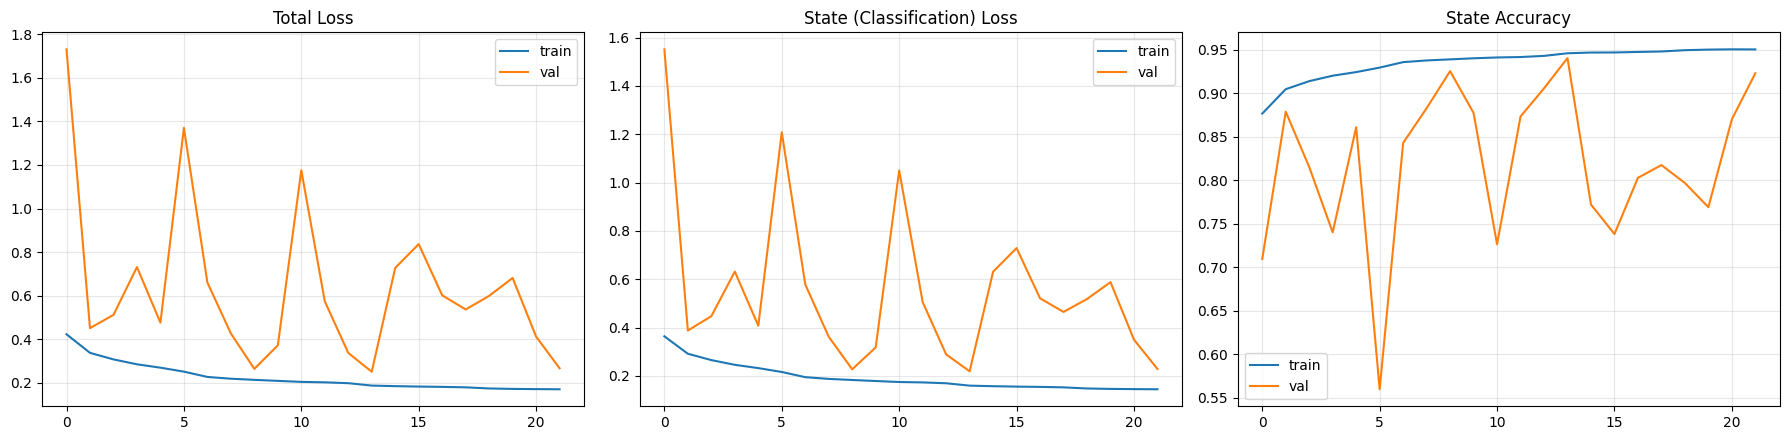

Saved: /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline/training_curves.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Total Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history.history["state_loss"], label="train")
axes[1].plot(history.history["val_state_loss"], label="val")
axes[1].set_title("State (Classification) Loss"); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(history.history["state_acc"], label="train")
axes[2].plot(history.history["val_state_acc"], label="val")
axes[2].set_title("State Accuracy"); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(CONFIG["checkpoint_dir"], "training_curves.png")
plt.savefig(plot_path, dpi=150)
plt.show()
print("Saved:", plot_path)

## 13. Dwell-Time Correction

In [ ]:
def apply_min_dwell_correction(state_sequence, min_dwell):
    corrected = state_sequence.copy()
    n = len(corrected)
    i = 0
    while i < n:
        j = i
        while j < n and corrected[j] == corrected[i]:
            j += 1
        run_length = j - i
        if run_length < min_dwell and 0 < i and j < n:
            if corrected[i - 1] == corrected[j] and corrected[i] != corrected[j]:
                corrected[i:j] = corrected[j]
        i = j
    return corrected

state_prob, duty_pred = model.predict(X_test_seq_s, verbose=0)
state_pred = (state_prob > 0.5).astype(int)
for i in range(len(CONFIG["appliances"])):
    state_pred[:, i] = apply_min_dwell_correction(state_pred[:, i], CONFIG["min_dwell_windows"])

## 14. Evaluation -- Appliance-Wise Accuracy, Precision, Recall, F1, MAE

In [ ]:
print(classification_report(Y_test_state, state_pred, target_names=CONFIG["appliances"], zero_division=0))

results = []
for i, app in enumerate(CONFIG["appliances"]):
    acc = accuracy_score(Y_test_state[:, i], state_pred[:, i])
    p = precision_score(Y_test_state[:, i], state_pred[:, i], zero_division=0)
    r = recall_score(Y_test_state[:, i], state_pred[:, i], zero_division=0)
    f1 = f1_score(Y_test_state[:, i], state_pred[:, i], zero_division=0)
    mae = mean_absolute_error(Y_test_duty[:, i], duty_pred[:, i])
    results.append({"appliance": app, "accuracy": acc, "precision": p, "recall": r, "f1": f1, "mae_duty": mae})
    print(f"  {app:20s} | Acc: {acc:.3f} | P: {p:.3f} | R: {r:.3f} | F1: {f1:.3f} | MAE(duty): {mae:.4f}")

results_df = pd.DataFrame(results)
avg_row = results_df.drop(columns="appliance").mean()
print("\n=== Average across 5 appliances ===")
print(avg_row.round(4))

                 precision    recall  f1-score   support

     dishwasher       0.69      0.97      0.81       948
washing machine       0.83      0.99      0.90      2798
         laptop       0.86      0.98      0.92     20429
         fridge       0.97      0.97      0.97     17180
  office lamp 1       0.51      0.90      0.65      5901

      micro avg       0.82      0.97      0.89     47256
      macro avg       0.77      0.96      0.85     47256
   weighted avg       0.85      0.97      0.90     47256
    samples avg       0.66      0.75      0.69     47256

  dishwasher           | Acc: 0.989 | P: 0.691 | R: 0.966 | F1: 0.806 | MAE(duty): 0.0098
  washing machine      | Acc: 0.985 | P: 0.831 | R: 0.989 | F1: 0.903 | MAE(duty): 0.0148
  laptop               | Acc: 0.905 | P: 0.858 | R: 0.982 | F1: 0.916 | MAE(duty): 0.1306
  fridge               | Acc: 0.973 | P: 0.966 | R: 0.974 | F1: 0.970 | MAE(duty): 0.0657
  office lamp 1        | Acc: 0.853 | P: 0.510 | R: 0.901 | F1: 0.6

## 15. Results Table

In [ ]:
results_display = results_df.copy()
avg_summary = pd.DataFrame([{"appliance": "AVERAGE", **avg_row.to_dict()}])
results_display = pd.concat([results_display, avg_summary], ignore_index=True)
results_display

,appliance,accuracy,precision,recall,f1,mae_duty
0,dishwasher,0.988598,0.691321,0.966245,0.805983,0.009841
1,washing machine,0.984669,0.831181,0.988921,0.903215,0.014777
2,laptop,0.904935,0.858132,0.982427,0.916083,0.130581
3,fridge,0.973396,0.965957,0.974447,0.970183,0.065695
4,office lamp 1,0.852918,0.510169,0.901203,0.651516,0.125559
5,AVERAGE,0.940903,0.771352,0.962649,0.849396,0.069291


## 16. Save Model & Results

In [ ]:
final_model_path = os.path.join(CONFIG["checkpoint_dir"], "final_model.keras")
model.save(final_model_path)

results_csv_path = os.path.join(CONFIG["checkpoint_dir"], "evaluation_results.csv")
results_display.to_csv(results_csv_path, index=False)

print("Model saved to:", final_model_path)
print("Best checkpoint at:", checkpoint_path)
print("Results CSV saved to:", results_csv_path)

Model saved to: /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline/final_model.keras
Best checkpoint at: /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline/best_model.keras
Results CSV saved to: /content/drive/MyDrive/SEM7PROJ/checkpoints_cnn_bilstm_baseline/evaluation_results.csv


## 17. Final Summary

In [ ]:
print("=" * 60)
print("EXPERIMENT SUMMARY -- CNN + BiLSTM")
print("=" * 60)
print("Attention: NO | Knowledge Vector: NO | Input: power signal only")
print("Appliances:", CONFIG["appliances"])
print()
print(f"Macro-average F1:        {avg_row['f1']:.4f}")
print(f"Macro-average Precision: {avg_row['precision']:.4f}")
print(f"Macro-average Recall:    {avg_row['recall']:.4f}")
print(f"Macro-average Accuracy:  {avg_row['accuracy']:.4f}")
print(f"Macro-average MAE(duty): {avg_row['mae_duty']:.4f}")
print("=" * 60)

EXPERIMENT SUMMARY -- CNN + BiLSTM
Attention: NO | Knowledge Vector: NO | Input: power signal only
Appliances: ['dishwasher', 'washing machine', 'laptop', 'fridge', 'office lamp 1']

Macro-average F1:        0.8494
Macro-average Precision: 0.7714
Macro-average Recall:    0.9626
Macro-average Accuracy:  0.9409
Macro-average MAE(duty): 0.0693
